In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Folder paths based on your VS Code structure
DATA_DIR = Path("Data")
OUTPUT_DIR = Path("Processed")

# Create output folder automatically
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load all five CSV files
customers = pd.read_csv(DATA_DIR / "customer_master.csv")

statistics = pd.read_csv(DATA_DIR / "dataset_statistics.csv")

sales = pd.read_csv(
    DATA_DIR / "ecommerce_sales_customer_analytics_150k.csv"
)

order_items = pd.read_csv(DATA_DIR / "order_items.csv")

products = pd.read_csv(DATA_DIR / "product_catalog.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [29]:
datasets = {
    "Customers": customers,
    "Statistics": statistics,
    "Sales": sales,
    "Order Items": order_items,
    "Products": products
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("-" * 40)
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Memory usage (MB):", round(df.memory_usage(deep=True).sum() / (1024**2), 2))


Customers
----------------------------------------
Rows: 25000
Columns: 11
Memory usage (MB): 3.68

Statistics
----------------------------------------
Rows: 1
Columns: 11
Memory usage (MB): 0.0

Sales
----------------------------------------
Rows: 138116
Columns: 46
Memory usage (MB): 75.29

Order Items
----------------------------------------
Rows: 397569
Columns: 12
Memory usage (MB): 44.36

Products
----------------------------------------
Rows: 1175
Columns: 9
Memory usage (MB): 0.2


In [30]:
for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(name.upper())
    print("=" * 60)

    report = pd.DataFrame({
        "Data Type": df.dtypes.astype(str),
        "Missing Values": df.isna().sum(),
        "Missing %": (df.isna().mean() * 100).round(2),
        "Unique Values": df.nunique()
    })

    display(report)


CUSTOMERS


,Data Type,Missing Values,Missing %,Unique Values
customer_id,str,0,0.0,25000
customer_name,str,0,0.0,21631
customer_age,int64,0,0.0,57
gender,str,0,0.0,3
customer_segment,str,0,0.0,4
customer_city,str,0,0.0,15555
customer_state,str,0,0.0,38
customer_country,str,0,0.0,7
region,str,0,0.0,5
customer_postal_code,int64,0,0.0,22183



STATISTICS


,Data Type,Missing Values,Missing %,Unique Values
Total Transactions,int64,0,0.0,1
Total Columns,int64,0,0.0,1
Total Customers,int64,0,0.0,1
Total Products Used,int64,0,0.0,1
Date Range,str,0,0.0,1
Total Revenue,str,0,0.0,1
Total Profit,str,0,0.0,1
Average Order Value,str,0,0.0,1
Average Rating,float64,0,0.0,1
Return Rate,str,0,0.0,1



SALES


,Data Type,Missing Values,Missing %,Unique Values
order_id,str,0,0.00,138116
order_date,str,0,0.00,1826
order_time,str,0,0.00,68991
order_status,str,0,0.00,4
sales_channel,str,0,0.00,4
customer_id,str,0,0.00,24911
customer_name,str,0,0.00,21564
customer_age,int64,0,0.00,57
gender,str,0,0.00,3
customer_segment,str,0,0.00,4



ORDER ITEMS


,Data Type,Missing Values,Missing %,Unique Values
order_id,str,0,0.0,138116
product_id,str,0,0.0,1175
quantity,int64,0,0.0,5
unit_price,float64,0,0.0,1164
discount_percentage,float64,0,0.0,343634
discount_amount,float64,0,0.0,50505
gross_sales,float64,0,0.0,5724
tax_amount,float64,0,0.0,29348
shipping_cost,float64,0,0.0,2851
net_sales,float64,0,0.0,125944



PRODUCTS


,Data Type,Missing Values,Missing %,Unique Values
product_id,str,0,0.0,1175
product_name,str,0,0.0,1175
product_category,str,0,0.0,15
product_subcategory,str,0,0.0,117
brand,str,0,0.0,144
supplier,str,0,0.0,10
unit_price,float64,0,0.0,1164
product_cost,float64,0,0.0,1147
product_rating,float64,0,0.0,25


In [31]:
print("Duplicate rows")
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()}")

print("\nOrder statuses:")
display(sales["order_status"].value_counts(dropna=False))

print("\nUnique customers in sales:", sales["customer_id"].nunique())
print("Unique products in catalogue:", products["product_id"].nunique())

Duplicate rows
Customers: 0
Statistics: 0
Sales: 0
Order Items: 0
Products: 0

Order statuses:


order_status
Completed    113559
Returned       9462
Cancelled      8398
Pending        6697
Name: count, dtype: int64


Unique customers in sales: 24911
Unique products in catalogue: 1175


In [32]:
print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())
print("Duplicate product IDs:", products["product_id"].duplicated().sum())

print("Order IDs in sales:", sales["order_id"].nunique())
print("Order IDs in order items:", order_items["order_id"].nunique())

Duplicate customer IDs: 0
Duplicate product IDs: 0
Order IDs in sales: 138116
Order IDs in order items: 138116


In [33]:
# Select relevant columns from the sales file
sales_selected = sales[
    [
        "order_id",
        "order_date",
        "order_status",
        "customer_id",
        "customer_segment"
    ]
].copy()

# Select relevant product information
products_selected = products[
    [
        "product_id",
        "product_name",
        "product_category",
        "product_subcategory",
        "brand",
        "unit_price",
        "product_rating"
    ]
].copy()

# First join: order items + sales information
merged = order_items.merge(
    sales_selected,
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Second join: add product information
merged = merged.merge(
    products_selected,
    on="product_id",
    how="left",
    validate="many_to_one",
    suffixes=("_order", "_product")
)

# Convert order_date to datetime
merged["order_date"] = pd.to_datetime(
    merged["order_date"],
    errors="coerce"
)

print("Merged dataset shape:", merged.shape)
display(merged.head())

Merged dataset shape: (397569, 22)


,order_id,product_id,quantity,unit_price_order,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit,order_date,order_status,customer_id,customer_segment,product_name,product_category,product_subcategory,brand,unit_price_product,product_rating
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12,2023-11-06,Completed,CUST-003102,Consumer,Garmin Total client-driven task-force Medical Devices,Health & Wellness,Medical Devices,Garmin,244.40,4.8
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92,2023-11-06,Completed,CUST-003102,Consumer,Tommy Hilfiger Open-architected full-range focus group Shoes,Fashion,Shoes,Tommy Hilfiger,287.13,3.0
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84,2025-12-24,Completed,CUST-003124,Premium,Swarovski Re-engineered discrete monitoring Earrings,Jewelry,Earrings,Swarovski,754.80,3.5
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37,2025-12-24,Completed,CUST-003124,Premium,NARS Enterprise-wide actuating firmware Fragrances,Beauty & Personal Care,Fragrances,NARS,31.36,4.0
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53,2021-07-05,Completed,CUST-012496,Premium,Mars Multi-tiered homogeneous artificial intelligence Pantry Staples,Grocery,Pantry Staples,Mars,6.31,3.0


In [34]:
print("Missing customer IDs:", merged["customer_id"].isna().sum())
print("Missing product names:", merged["product_name"].isna().sum())
print("Missing product categories:", merged["product_category"].isna().sum())
print("Missing order dates:", merged["order_date"].isna().sum())

print("\nOrder status counts:")
display(merged["order_status"].value_counts(dropna=False))

print("\nRows before and after merging:")
print("Order items:", len(order_items))
print("Merged:", len(merged))

Missing customer IDs: 0
Missing product names: 0
Missing product categories: 0
Missing order dates: 0

Order status counts:


order_status
Completed    327028
Returned      27209
Cancelled     24109
Pending       19223
Name: count, dtype: int64


Rows before and after merging:
Order items: 397569
Merged: 397569


In [35]:
# Standardise status text for filtering
status = merged["order_status"].astype("string").str.strip().str.lower()

# Keep completed orders with valid customer/product identifiers
interactions = merged.loc[
    status.eq("completed")
    & merged["customer_id"].notna()
    & merged["product_id"].notna()
    & merged["product_name"].notna()
].copy()

# Remove rows with invalid purchase quantities
interactions["quantity"] = pd.to_numeric(
    interactions["quantity"],
    errors="coerce"
)

interactions = interactions.loc[
    interactions["quantity"].gt(0)
].copy()

# Save both datasets
merged.to_csv(
    OUTPUT_DIR / "merged_recommendation_data.csv",
    index=False
)

interactions.to_csv(
    OUTPUT_DIR / "user_item_interactions.csv",
    index=False
)

print("Merged data saved successfully.")
print("Completed-purchase interaction rows:", len(interactions))
print("Unique customers:", interactions["customer_id"].nunique())
print("Unique products:", interactions["product_id"].nunique())

Merged data saved successfully.
Completed-purchase interaction rows: 327028
Unique customers: 24748
Unique products: 1175


In [36]:
datasets = {
    "Customers": customers,
    "Statistics": statistics,
    "Sales": sales,
    "Order Items": order_items,
    "Products": products
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {name}")
    print("=" * 60)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


DATASET: Customers
Shape: (25000, 11)
Columns: ['customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'customer_acquisition_cost']


,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53



DATASET: Statistics
Shape: (1, 11)
Columns: ['Total Transactions', 'Total Columns', 'Total Customers', 'Total Products Used', 'Date Range', 'Total Revenue', 'Total Profit', 'Average Order Value', 'Average Rating', 'Return Rate', 'Cancellation Rate']


,Total Transactions,Total Columns,Total Customers,Total Products Used,Date Range,Total Revenue,Total Profit,Average Order Value,Average Rating,Return Rate,Cancellation Rate
0,138116,46,24911,138116,2021-01-01 to 2025-12-31,"$177,134,263.74","$76,146,395.76","$1,282.50",3.68,6.85%,6.08%



DATASET: Sales
Shape: (138116, 46)
Columns: ['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel', 'customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_type', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'payment_method', 'payment_status', 'currency', 'shipping_method', 'warehouse', 'delivery_days', 'estimated_delivery_days', 'delivery_status', 'return_status', 'return_reason', 'customer_rating', 'review_sentiment', 'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code', 'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit', 'profit_margin_percentage', 'customer_lifetime_value', 'is_repeat_customer', 'customer_order_count']


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,3.0,3.0,On Time,NaN,NaN,3.5,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,10.0,10.0,On Time,NaN,NaN,3.6,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,19993,Cash on Delivery,Paid,USD,Express,WH-015,3.0,3.0,On Time,NaN,NaN,4.3,Positive,Good product. Works as expected.,YouTube,NaN,NaN,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6



DATASET: Order Items
Shape: (397569, 12)
Columns: ['order_id', 'product_id', 'quantity', 'unit_price', 'discount_percentage', 'discount_amount', 'gross_sales', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit']


,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84



DATASET: Products
Shape: (1175, 9)
Columns: ['product_id', 'product_name', 'product_category', 'product_subcategory', 'brand', 'supplier', 'unit_price', 'product_cost', 'product_rating']


,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.90,474.06,4.3
1,PROD-000002,Google User-centric even-keeled encryption Smartphones,Electronics,Smartphones,Google,Euro Logistics,978.26,519.66,2.9
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.51,185.48,3.9


In [37]:
for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(name.upper())
    print("=" * 60)

    categorical = df.select_dtypes(
        include=["object", "category", "bool", "string"]
    ).columns.tolist()

    numerical = df.select_dtypes(
        include=["number"]
    ).columns.tolist()

    datetime_cols = df.select_dtypes(
        include=["datetime"]
    ).columns.tolist()

    print("Categorical / text columns:")
    print(categorical)

    print("\nNumerical columns:")
    print(numerical)

    print("\nDatetime columns:")
    print(datetime_cols)


CUSTOMERS
Categorical / text columns:
['customer_id', 'customer_name', 'gender', 'customer_segment', 'customer_city', 'customer_state', 'customer_country', 'region']

Numerical columns:
['customer_age', 'customer_postal_code', 'customer_acquisition_cost']

Datetime columns:
[]

STATISTICS
Categorical / text columns:
['Date Range', 'Total Revenue', 'Total Profit', 'Average Order Value', 'Return Rate', 'Cancellation Rate']

Numerical columns:
['Total Transactions', 'Total Columns', 'Total Customers', 'Total Products Used', 'Average Rating']

Datetime columns:
[]

SALES
Categorical / text columns:
['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel', 'customer_id', 'customer_name', 'gender', 'customer_segment', 'customer_type', 'customer_city', 'customer_state', 'customer_country', 'region', 'payment_method', 'payment_status', 'currency', 'shipping_method', 'warehouse', 'delivery_status', 'return_status', 'return_reason', 'review_sentiment', 'customer_review', 'market

In [38]:
for name, df in datasets.items():
    print(f"\n{name}")

    missing = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (
            df.isnull().mean() * 100
        ).round(2)
    })

    missing = missing[missing["Missing_Count"] > 0]
    display(missing.sort_values(
        "Missing_Percentage",
        ascending=False
    ))


Customers


,Missing_Count,Missing_Percentage



Statistics


,Missing_Count,Missing_Percentage



Sales


,Missing_Count,Missing_Percentage
return_status,128654,93.15
return_reason,128654,93.15
coupon_code,110502,80.01
campaign_name,83233,60.26
delivery_days,24557,17.78
customer_rating,24557,17.78
estimated_delivery_days,24557,17.78
customer_review,24557,17.78
review_sentiment,24557,17.78



Order Items


,Missing_Count,Missing_Percentage



Products


,Missing_Count,Missing_Percentage


In [39]:
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )

Customers: 0 duplicate rows
Statistics: 0 duplicate rows
Sales: 0 duplicate rows
Order Items: 0 duplicate rows
Products: 0 duplicate rows


In [40]:
print("Duplicate customer IDs:",
      customers["customer_id"].duplicated().sum())

print("Duplicate product IDs:",
      products["product_id"].duplicated().sum())

print("Unique order IDs in sales:",
      sales["order_id"].nunique())

print("Unique order IDs in order items:",
      order_items["order_id"].nunique())

print("Unique products in catalogue:",
      products["product_id"].nunique())

print("Unique products in order items:",
      order_items["product_id"].nunique())

Duplicate customer IDs: 0
Duplicate product IDs: 0
Unique order IDs in sales: 138116
Unique order IDs in order items: 138116
Unique products in catalogue: 1175
Unique products in order items: 1175


## Data Cleaning


In [41]:
# Check whether every order item matches a sales order
unmatched_orders = ~order_items["order_id"].isin(sales["order_id"])

# Check whether every order item matches a catalogue product
unmatched_products = ~order_items["product_id"].isin(products["product_id"])

print("Unmatched order items:", unmatched_orders.sum())
print("Unmatched product IDs:", unmatched_products.sum())

print("\nOrder status distribution:")
display(sales["order_status"].value_counts(dropna=False))

Unmatched order items: 0
Unmatched product IDs: 0

Order status distribution:


order_status
Completed    113559
Returned       9462
Cancelled      8398
Pending        6697
Name: count, dtype: int64

In [42]:
# Keep only relevant columns from sales
sales_selected = sales[
    [
        "order_id",
        "order_date",
        "order_status",
        "customer_id",
        "customer_segment"
    ]
].copy()

# Keep only relevant product information
products_selected = products[
    [
        "product_id",
        "product_name",
        "product_category",
        "product_subcategory",
        "brand",
        "unit_price",
        "product_rating"
    ]
].copy()

# Merge order items with sales
merged = order_items.merge(
    sales_selected,
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Add product details
merged = merged.merge(
    products_selected,
    on="product_id",
    how="left",
    validate="many_to_one",
    suffixes=("_item", "_catalog")
)

# Convert the order date to datetime
merged["order_date"] = pd.to_datetime(
    merged["order_date"],
    errors="coerce"
)

print("Original order-item rows:", len(order_items))
print("Merged rows:", len(merged))
print("Merged columns:", len(merged.columns))

display(merged.head())

Original order-item rows: 397569
Merged rows: 397569
Merged columns: 22


,order_id,product_id,quantity,unit_price_item,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit,order_date,order_status,customer_id,customer_segment,product_name,product_category,product_subcategory,brand,unit_price_catalog,product_rating
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12,2023-11-06,Completed,CUST-003102,Consumer,Garmin Total client-driven task-force Medical Devices,Health & Wellness,Medical Devices,Garmin,244.40,4.8
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92,2023-11-06,Completed,CUST-003102,Consumer,Tommy Hilfiger Open-architected full-range focus group Shoes,Fashion,Shoes,Tommy Hilfiger,287.13,3.0
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84,2025-12-24,Completed,CUST-003124,Premium,Swarovski Re-engineered discrete monitoring Earrings,Jewelry,Earrings,Swarovski,754.80,3.5
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37,2025-12-24,Completed,CUST-003124,Premium,NARS Enterprise-wide actuating firmware Fragrances,Beauty & Personal Care,Fragrances,NARS,31.36,4.0
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53,2021-07-05,Completed,CUST-012496,Premium,Mars Multi-tiered homogeneous artificial intelligence Pantry Staples,Grocery,Pantry Staples,Mars,6.31,3.0


In [43]:
# Standardise status text
status = (
    merged["order_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert quantity to numeric
merged["quantity"] = pd.to_numeric(
    merged["quantity"],
    errors="coerce"
)

# Select valid completed purchases
interactions = merged.loc[
    status.eq("completed")
    & merged["customer_id"].notna()
    & merged["product_id"].notna()
    & merged["product_name"].notna()
    & merged["quantity"].gt(0)
].copy()

print("Merged rows:", len(merged))
print("Valid completed-purchase rows:", len(interactions))
print("Unique customers:", interactions["customer_id"].nunique())
print("Unique products:", interactions["product_id"].nunique())

display(interactions.head())

Merged rows: 397569
Valid completed-purchase rows: 327028
Unique customers: 24748
Unique products: 1175


,order_id,product_id,quantity,unit_price_item,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit,order_date,order_status,customer_id,customer_segment,product_name,product_category,product_subcategory,brand,unit_price_catalog,product_rating
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12,2023-11-06,Completed,CUST-003102,Consumer,Garmin Total client-driven task-force Medical Devices,Health & Wellness,Medical Devices,Garmin,244.40,4.8
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92,2023-11-06,Completed,CUST-003102,Consumer,Tommy Hilfiger Open-architected full-range focus group Shoes,Fashion,Shoes,Tommy Hilfiger,287.13,3.0
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84,2025-12-24,Completed,CUST-003124,Premium,Swarovski Re-engineered discrete monitoring Earrings,Jewelry,Earrings,Swarovski,754.80,3.5
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37,2025-12-24,Completed,CUST-003124,Premium,NARS Enterprise-wide actuating firmware Fragrances,Beauty & Personal Care,Fragrances,NARS,31.36,4.0
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53,2021-07-05,Completed,CUST-012496,Premium,Mars Multi-tiered homogeneous artificial intelligence Pantry Staples,Grocery,Pantry Staples,Mars,6.31,3.0


In [44]:
from pathlib import Path

OUTPUT_DIR = Path("Processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

merged.to_csv(
    OUTPUT_DIR / "merged_recommendation_data.csv",
    index=False
)

interactions.to_csv(
    OUTPUT_DIR / "user_item_interactions.csv",
    index=False
)

print("Files saved successfully:")
print(OUTPUT_DIR / "merged_recommendation_data.csv")
print(OUTPUT_DIR / "user_item_interactions.csv")

Files saved successfully:
Processed\merged_recommendation_data.csv
Processed\user_item_interactions.csv


## Analyse


In [45]:
# Number of purchases per customer
customer_purchases = interactions.groupby("customer_id").size()

# Number of purchases per product
product_purchases = interactions.groupby("product_id").size()

print("Average purchase records per customer:",
      round(customer_purchases.mean(), 2))

print("Average purchase records per product:",
      round(product_purchases.mean(), 2))

print("\nTop 10 most purchased products:")

top_products = (
    interactions.groupby(["product_id", "product_name"])["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="total_quantity")
)

display(top_products)

Average purchase records per customer: 13.21
Average purchase records per product: 278.32

Top 10 most purchased products:


,product_id,product_name,total_quantity
0,PROD-000839,Arm & Hammer Organized maximized software Grooming,740
1,PROD-000694,Goodyear Managed clear-thinking secured line Tools,729
2,PROD-000549,HarperCollins Operative multi-tasking budgetary management Movies,727
3,PROD-000878,Graco Networked reciprocal instruction set Diapers,720
4,PROD-001082,Kraft Heinz Progressive client-driven info-mediaries Frozen Foods,720
5,PROD-000449,Adidas Public-key homogeneous functionalities Team Sports,719
6,PROD-000928,Evenflo Customizable content-based adapter Strollers,711
7,PROD-000734,Philips Face-to-face 4thgeneration functionalities Medical Devices,711
8,PROD-000013,HP Adaptive well-modulated workforce Smartphones,710
9,PROD-000114,LG Adaptive human-resource firmware Air Conditioners,702


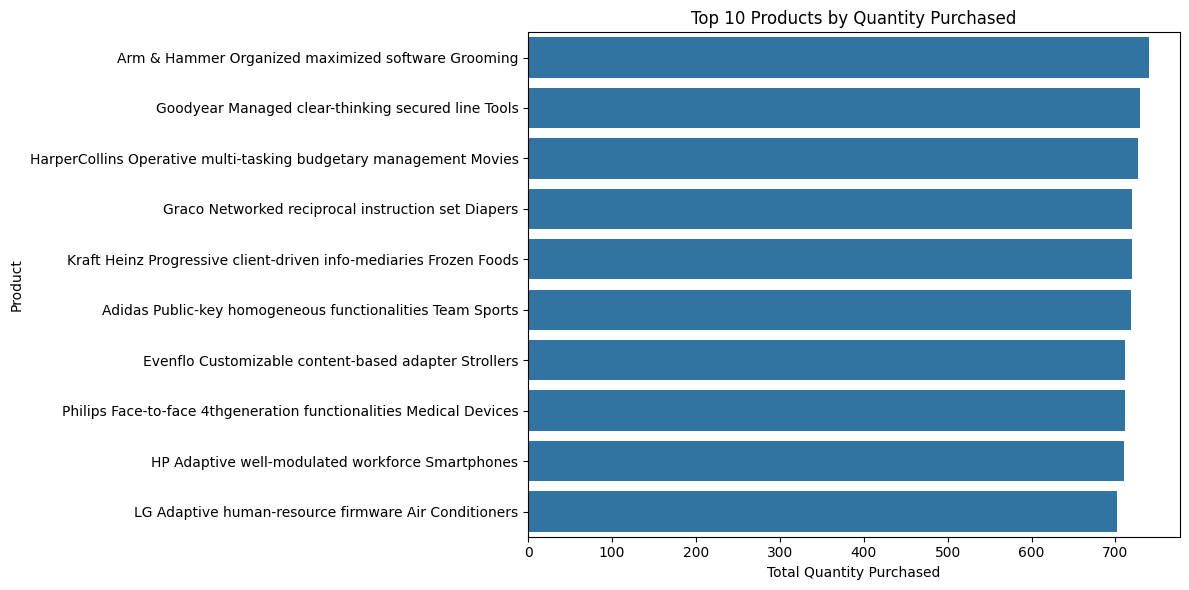

In [46]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="total_quantity",
    y="product_name"
)

plt.title("Top 10 Products by Quantity Purchased")
plt.xlabel("Total Quantity Purchased")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


,product_category,quantity
0,Sports & Outdoors,54005
1,Books & Media,51883
2,Health & Wellness,51829
3,Beauty & Personal Care,49974
4,Automotive,48280
5,Office Supplies,48019
6,Home Appliances,47094
7,Toys & Games,46651
8,Grocery,46634
9,Electronics,46532


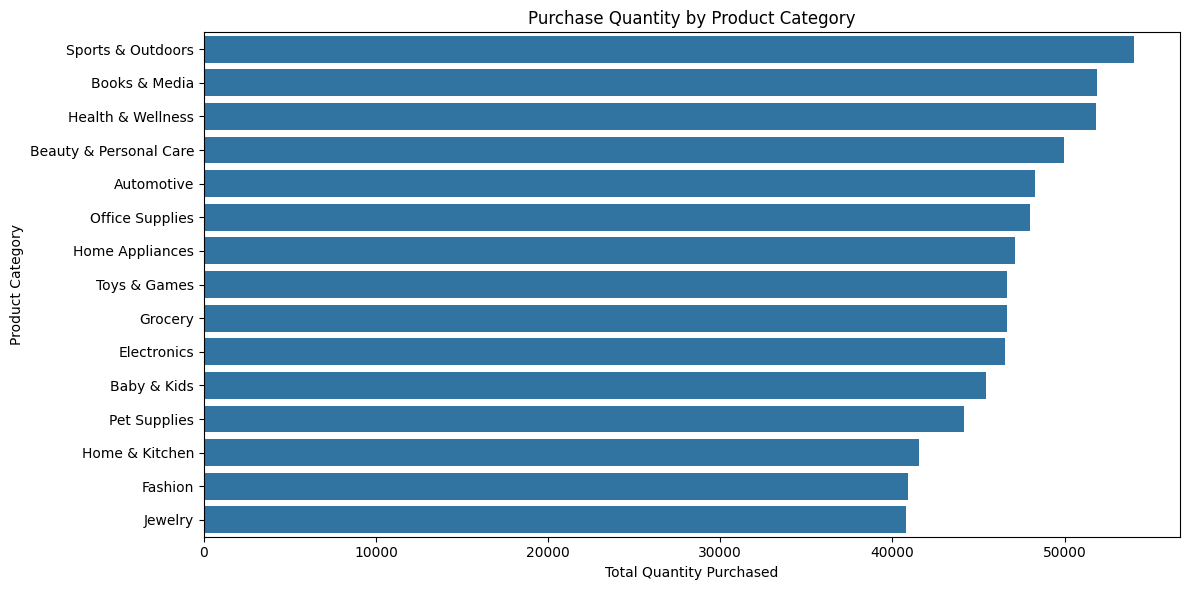

In [47]:
category_sales = (
    interactions.groupby("product_category")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(category_sales)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_sales,
    x="quantity",
    y="product_category"
)

plt.title("Purchase Quantity by Product Category")
plt.xlabel("Total Quantity Purchased")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


,total_order_lines,unique_products,total_quantity
count,24748.00,24748.00,24748.00
mean,13.21,13.14,28.44
std,6.83,6.75,15.41
min,1.00,1.00,1.00
25%,8.00,8.00,17.00
50%,12.00,12.00,27.00
75%,17.00,17.00,38.00
max,52.00,51.00,117.00


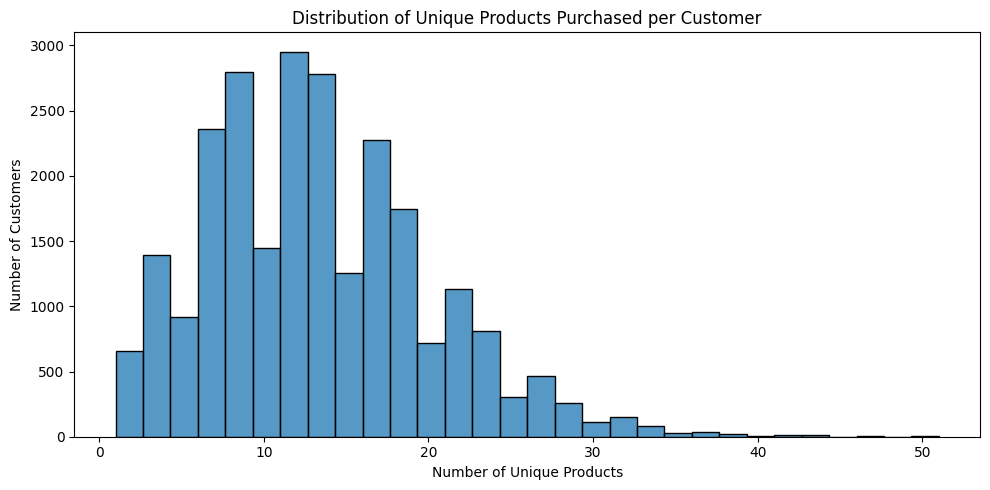

In [48]:
customer_summary = (
    interactions.groupby("customer_id")
    .agg(
        total_order_lines=("product_id", "size"),
        unique_products=("product_id", "nunique"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
)

display(customer_summary.describe().round(2))

plt.figure(figsize=(10, 5))

sns.histplot(
    customer_summary["unique_products"],
    bins=30
)

plt.title("Distribution of Unique Products Purchased per Customer")
plt.xlabel("Number of Unique Products")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [49]:
top_products.to_csv(
    OUTPUT_DIR / "top_10_products.csv",
    index=False
)

category_sales.to_csv(
    OUTPUT_DIR / "category_purchase_summary.csv",
    index=False
)

customer_summary.to_csv(
    OUTPUT_DIR / "customer_purchase_summary.csv",
    index=False
)

print("EDA summary files saved successfully!")

EDA summary files saved successfully!


In [50]:
# Count distinct customers who purchased each product
popularity = (
    interactions.groupby(
        ["product_id", "product_name", "product_category"]
    )
    .agg(
        unique_customers=("customer_id", "nunique"),
        total_quantity=("quantity", "sum"),
        purchase_records=("order_id", "size")
    )
    .reset_index()
    .sort_values(
        by=["unique_customers", "total_quantity"],
        ascending=False
    )
)

print("Popularity model created!")
display(popularity.head(10))

Popularity model created!


,product_id,product_name,product_category,unique_customers,total_quantity,purchase_records
838,PROD-000839,Arm & Hammer Organized maximized software Grooming,Pet Supplies,331,740,333
583,PROD-000584,Spin Master Versatile interactive success Educational Toys,Toys & Games,331,694,337
448,PROD-000449,Adidas Public-key homogeneous functionalities Team Sports,Sports & Outdoors,328,719,329
693,PROD-000694,Goodyear Managed clear-thinking secured line Tools,Automotive,325,729,327
1081,PROD-001082,Kraft Heinz Progressive client-driven info-mediaries Frozen Foods,Grocery,325,720,326
938,PROD-000939,Chicco Quality-focused heuristic service-desk Strollers,Baby & Kids,321,652,321
733,PROD-000734,Philips Face-to-face 4thgeneration functionalities Medical Devices,Health & Wellness,320,711,326
502,PROD-000503,McGraw-Hill Synergistic hybrid website Academic,Books & Media,320,680,322
524,PROD-000525,Pearson Seamless incremental focus group Comics,Books & Media,319,677,322
639,PROD-000640,Castrol Reverse-engineered impactful moderator Car Accessories,Automotive,319,671,321


In [51]:
def recommend_popular(top_n=10, exclude_products=None):
    """
    Recommend popular products based on training interactions.
    Optionally exclude products the customer has already purchased.
    """
    results = popularity.copy()

    if exclude_products is not None:
        results = results[
            ~results["product_id"].isin(exclude_products)
        ]

    return results.head(top_n)[
        [
            "product_id",
            "product_name",
            "product_category",
            "unique_customers",
            "total_quantity"
        ]
    ]


# Try the model
display(recommend_popular(top_n=10))

,product_id,product_name,product_category,unique_customers,total_quantity
838,PROD-000839,Arm & Hammer Organized maximized software Grooming,Pet Supplies,331,740
583,PROD-000584,Spin Master Versatile interactive success Educational Toys,Toys & Games,331,694
448,PROD-000449,Adidas Public-key homogeneous functionalities Team Sports,Sports & Outdoors,328,719
693,PROD-000694,Goodyear Managed clear-thinking secured line Tools,Automotive,325,729
1081,PROD-001082,Kraft Heinz Progressive client-driven info-mediaries Frozen Foods,Grocery,325,720
938,PROD-000939,Chicco Quality-focused heuristic service-desk Strollers,Baby & Kids,321,652
733,PROD-000734,Philips Face-to-face 4thgeneration functionalities Medical Devices,Health & Wellness,320,711
502,PROD-000503,McGraw-Hill Synergistic hybrid website Academic,Books & Media,320,680
524,PROD-000525,Pearson Seamless incremental focus group Comics,Books & Media,319,677
639,PROD-000640,Castrol Reverse-engineered impactful moderator Car Accessories,Automotive,319,671


In [52]:
print("Earliest order:", interactions["order_date"].min())
print("Latest order:", interactions["order_date"].max())

print("\nPurchases per year:")
display(
    interactions.groupby(
        interactions["order_date"].dt.year
    )["order_id"].nunique().rename("unique_orders")
)

Earliest order: 2021-01-01 00:00:00
Latest order: 2025-12-31 00:00:00

Purchases per year:


order_date
2021    22835
2022    22659
2023    22722
2024    22670
2025    22673
Name: unique_orders, dtype: int64

In [53]:
print("Earliest order:", interactions["order_date"].min())
print("Latest order:", interactions["order_date"].max())

display(
    interactions.groupby(
        interactions["order_date"].dt.year
    )["order_id"].nunique().rename("unique_orders")
)

Earliest order: 2021-01-01 00:00:00
Latest order: 2025-12-31 00:00:00


order_date
2021    22835
2022    22659
2023    22722
2024    22670
2025    22673
Name: unique_orders, dtype: int64

In [54]:
# Ensure order_date is datetime
interactions["order_date"] = pd.to_datetime(
    interactions["order_date"],
    errors="coerce"
)

# Remove records with invalid dates
model_data = interactions.dropna(
    subset=["order_date", "customer_id", "product_id"]
).copy()

# Time-based split
train = model_data[
    model_data["order_date"] < "2025-01-01"
].copy()

test = model_data[
    (model_data["order_date"] >= "2025-01-01")
    & (model_data["order_date"] < "2026-01-01")
].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("Training customers:", train["customer_id"].nunique())
print("Testing customers:", test["customer_id"].nunique())

print("Training products:", train["product_id"].nunique())
print("Testing products:", test["product_id"].nunique())

Training rows: 261894
Testing rows: 65134
Training customers: 24349
Testing customers: 14892
Training products: 1175
Testing products: 1175


In [55]:
print("Latest training date:", train["order_date"].max())
print("Earliest testing date:", test["order_date"].min())

assert train["order_date"].max() < test["order_date"].min()

print("Time-based split verified successfully!")

Latest training date: 2024-12-31 00:00:00
Earliest testing date: 2025-01-01 00:00:00
Time-based split verified successfully!


In [56]:
popularity_model = (
    train.groupby(
        ["product_id", "product_name", "product_category"]
    )
    .agg(
        unique_customers=("customer_id", "nunique"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
    .sort_values(
        ["unique_customers", "total_quantity"],
        ascending=False
    )
)

def recommend_popular(top_n=10, exclude_products=None):
    results = popularity_model.copy()

    if exclude_products is not None:
        results = results[
            ~results["product_id"].isin(exclude_products)
        ]

    return results.head(top_n)

display(recommend_popular(10))

,product_id,product_name,product_category,unique_customers,total_quantity
693,PROD-000694,Goodyear Managed clear-thinking secured line Tools,Automotive,271,615
733,PROD-000734,Philips Face-to-face 4thgeneration functionalities Medical Devices,Health & Wellness,271,608
448,PROD-000449,Adidas Public-key homogeneous functionalities Team Sports,Sports & Outdoors,271,592
838,PROD-000839,Arm & Hammer Organized maximized software Grooming,Pet Supplies,270,614
938,PROD-000939,Chicco Quality-focused heuristic service-desk Strollers,Baby & Kids,265,547
1028,PROD-001029,P&G Integrated uniform adapter Beverages,Grocery,264,547
699,PROD-000700,Bosch Mandatory zero administration matrix Tools,Automotive,262,564
583,PROD-000584,Spin Master Versatile interactive success Educational Toys,Toys & Games,261,546
393,PROD-000394,Adidas Phased grid-enabled installation Camping,Sports & Outdoors,260,542
769,PROD-000770,Johnson & Johnson Total mission-critical product Massagers,Health & Wellness,259,567


In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Use only product information available in the catalogue
product_features = products[
    [
        "product_id",
        "product_name",
        "product_category",
        "product_subcategory",
        "brand"
    ]
].copy()

# Handle missing text values
text_columns = [
    "product_name",
    "product_category",
    "product_subcategory",
    "brand"
]

for col in text_columns:
    product_features[col] = (
        product_features[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

# Combine product information into one text feature
product_features["combined_features"] = (
    product_features["product_name"] + " "
    + product_features["product_category"] + " "
    + product_features["product_subcategory"] + " "
    + product_features["brand"]
)

print("Product features prepared:", product_features.shape)
display(product_features.head())

Product features prepared: (1175, 6)


,product_id,product_name,product_category,product_subcategory,brand,combined_features
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Apple Sharable bifurcated algorithm Smartphones Electronics Smartphones Apple
1,PROD-000002,Google User-centric even-keeled encryption Smartphones,Electronics,Smartphones,Google,Google User-centric even-keeled encryption Smartphones Electronics Smartphones Google
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,LG Face-to-face client-driven support Smartphones Electronics Smartphones LG
3,PROD-000004,Sony Customer-focused systematic support Smartphones,Electronics,Smartphones,Sony,Sony Customer-focused systematic support Smartphones Electronics Smartphones Sony
4,PROD-000005,OnePlus Quality-focused background parallelism Smartphones,Electronics,Smartphones,OnePlus,OnePlus Quality-focused background parallelism Smartphones Electronics Smartphones OnePlus


In [58]:
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=10000
)

tfidf_matrix = tfidf.fit_transform(
    product_features["combined_features"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of products:", tfidf_matrix.shape[0])
print("Number of text features:", tfidf_matrix.shape[1])

TF-IDF matrix shape: (1175, 6118)
Number of products: 1175
Number of text features: 6118


In [59]:
similarity_matrix = cosine_similarity(tfidf_matrix)

print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (1175, 1175)


In [60]:
# Map product IDs to their row positions
product_index = pd.Series(
    product_features.index,
    index=product_features["product_id"]
).drop_duplicates()


def recommend_similar_products(product_id, top_n=10):
    if product_id not in product_index.index:
        print("Product ID not found.")
        return pd.DataFrame()

    idx = product_index.loc[product_id]

    # Similarity scores for the selected product
    scores = similarity_matrix[idx]

    # Highest similarity first; exclude the selected product
    ranked_indices = np.argsort(scores)[::-1]
    ranked_indices = [
        i for i in ranked_indices if i != idx
    ][:top_n]

    recommendations = product_features.iloc[
        ranked_indices
    ][
        [
            "product_id",
            "product_name",
            "product_category",
            "product_subcategory",
            "brand"
        ]
    ].copy()

    recommendations["similarity_score"] = [
        scores[i] for i in ranked_indices
    ]

    return recommendations.reset_index(drop=True)

In [61]:
# Choose one product from the catalogue
sample_product = product_features.iloc[0]

print("Selected product:")
display(sample_product.to_frame().T)

print("\nRecommended similar products:")

display(
    recommend_similar_products(
        sample_product["product_id"],
        top_n=10
    )
)

Selected product:


,product_id,product_name,product_category,product_subcategory,brand,combined_features
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Apple Sharable bifurcated algorithm Smartphones Electronics Smartphones Apple



Recommended similar products:


,product_id,product_name,product_category,product_subcategory,brand,similarity_score
0,PROD-000006,Apple Optimized 5thgeneration algorithm Smartphones,Electronics,Smartphones,Apple,0.667103
1,PROD-000008,Samsung Profit-focused real-time algorithm Smartphones,Electronics,Smartphones,Samsung,0.366977
2,PROD-000009,LG Realigned dedicated structure Smartphones,Electronics,Smartphones,LG,0.276186
3,PROD-000013,HP Adaptive well-modulated workforce Smartphones,Electronics,Smartphones,HP,0.271060
4,PROD-000010,Asus Streamlined tangible moratorium Smartphones,Electronics,Smartphones,Asus,0.269027
5,PROD-000012,LG Reverse-engineered even-keeled workforce Smartphones,Electronics,Smartphones,LG,0.267606
6,PROD-000011,Samsung Operative directional knowledge user Smartphones,Electronics,Smartphones,Samsung,0.266666
7,PROD-000015,Microsoft Mandatory even-keeled collaboration Smartphones,Electronics,Smartphones,Microsoft,0.263201
8,PROD-000004,Sony Customer-focused systematic support Smartphones,Electronics,Smartphones,Sony,0.261343
9,PROD-000005,OnePlus Quality-focused background parallelism Smartphones,Electronics,Smartphones,OnePlus,0.260528


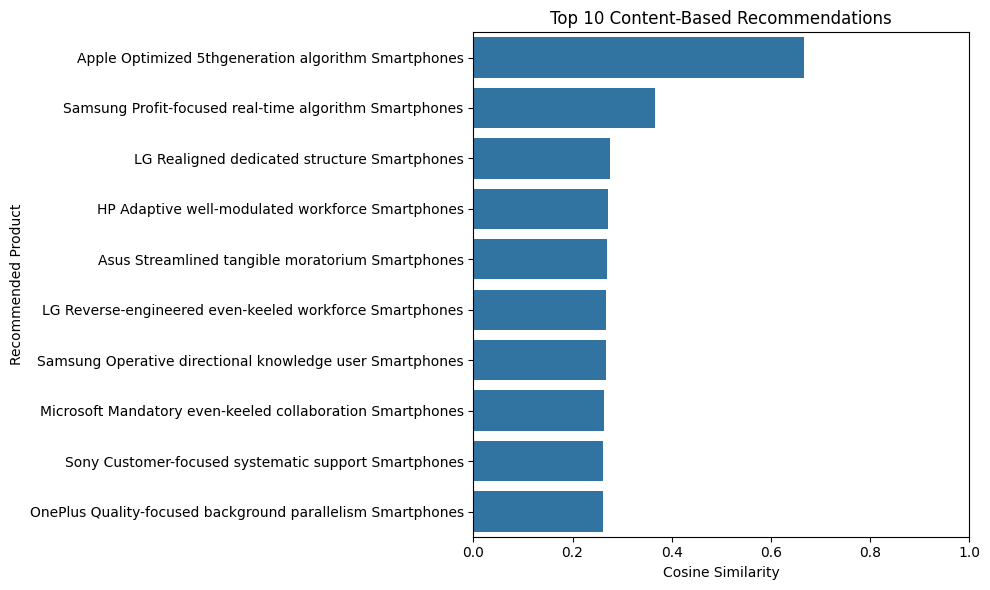

In [62]:
sample_recommendations = recommend_similar_products(
    sample_product["product_id"],
    top_n=10
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=sample_recommendations,
    x="similarity_score",
    y="product_name"
)

plt.title("Top 10 Content-Based Recommendations")
plt.xlabel("Cosine Similarity")
plt.ylabel("Recommended Product")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [63]:
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD

# Aggregate repeated purchases of the same product by a customer
train_interactions = (
    train.groupby(["customer_id", "product_id"])
    .agg(quantity=("quantity", "sum"))
    .reset_index()
)

print("Unique customer-product interactions:", len(train_interactions))
display(train_interactions.head())

Unique customer-product interactions: 260665


,customer_id,product_id,quantity
0,CUST-000001,PROD-000024,2
1,CUST-000001,PROD-000177,5
2,CUST-000001,PROD-000233,1
3,CUST-000001,PROD-000595,2
4,CUST-000001,PROD-000600,1


In [64]:
# Map customers and products to matrix positions
customer_ids = train_interactions["customer_id"].unique()
product_ids = products["product_id"].unique()

customer_to_idx = {
    customer_id: idx
    for idx, customer_id in enumerate(customer_ids)
}

product_to_idx = {
    product_id: idx
    for idx, product_id in enumerate(product_ids)
}

# Convert interactions into matrix coordinates
rows = train_interactions["customer_id"].map(customer_to_idx).to_numpy()
cols = train_interactions["product_id"].map(product_to_idx).to_numpy()
values = train_interactions["quantity"].to_numpy(dtype=float)

interaction_matrix = csr_matrix(
    (values, (rows, cols)),
    shape=(len(customer_ids), len(product_ids))
)

print("Interaction matrix shape:", interaction_matrix.shape)
print("Non-zero interactions:", interaction_matrix.nnz)
print(
    "Matrix density:",
    round(
        interaction_matrix.nnz /
        (interaction_matrix.shape[0] * interaction_matrix.shape[1]) * 100,
        2
    ),
    "%"
)

Interaction matrix shape: (24349, 1175)
Non-zero interactions: 260665
Matrix density: 0.91 %


In [65]:
svd_model = TruncatedSVD(
    n_components=50,
    random_state=42,
    n_iter=7
)

customer_factors = svd_model.fit_transform(interaction_matrix)
product_factors = svd_model.components_.T

print("Customer factors shape:", customer_factors.shape)
print("Product factors shape:", product_factors.shape)

print(
    "Explained variance ratio:",
    round(svd_model.explained_variance_ratio_.sum(), 4)
)

Customer factors shape: (24349, 50)
Product factors shape: (1175, 50)
Explained variance ratio: 0.0639


In [66]:
# Product catalogue indexed by product ID
product_lookup = products.set_index("product_id")


def recommend_collaborative(customer_id, top_n=10):
    if customer_id not in customer_to_idx:
        print("Customer not found in training data.")
        return pd.DataFrame()

    customer_idx = customer_to_idx[customer_id]

    # Score every product for this customer
    scores = (
        customer_factors[customer_idx] @ product_factors.T
    )

    # Exclude products already purchased in training
    purchased = set(
        train_interactions.loc[
            train_interactions["customer_id"] == customer_id,
            "product_id"
        ]
    )

    ranked_indices = np.argsort(scores)[::-1]

    recommended_ids = [
        product_ids[idx]
        for idx in ranked_indices
        if product_ids[idx] not in purchased
    ][:top_n]

    result = product_lookup.loc[recommended_ids].reset_index()

    result["recommendation_score"] = [
        float(scores[product_to_idx[pid]])
        for pid in recommended_ids
    ]

    return result[
        [
            "product_id",
            "product_name",
            "product_category",
            "brand",
            "recommendation_score"
        ]
    ]

In [67]:
# Choose a customer who appears in training data
sample_customer = customer_ids[0]

print("Sample customer:", sample_customer)

display(
    recommend_collaborative(
        sample_customer,
        top_n=10
    )
)

Sample customer: CUST-000001


,product_id,product_name,product_category,brand,recommendation_score
0,PROD-000260,Kiehl's Pre-emptive 4thgeneration info-mediaries Fragrances,Beauty & Personal Care,Kiehl's,0.222589
1,PROD-001085,Unilever Organized holistic array Frozen Foods,Grocery,Unilever,0.215463
2,PROD-000713,Castrol Organic reciprocal forecast Cleaning,Automotive,Castrol,0.212540
3,PROD-000178,Zara Exclusive logistical hardware Kids' Clothing,Fashion,Zara,0.198086
4,PROD-000814,Petmate Networked next generation capability Pet Toys,Pet Supplies,Petmate,0.183284
5,PROD-000322,Wayfair Implemented directional initiative Bedding,Home & Kitchen,Wayfair,0.170477
6,PROD-001016,Mikimoto Progressive tertiary hierarchy Gemstones,Jewelry,Mikimoto,0.165749
7,PROD-001067,PepsiCo Switchable multi-state definition Produce,Grocery,PepsiCo,0.164979
8,PROD-000534,McGraw-Hill Sharable radical adapter Audiobooks,Books & Media,McGraw-Hill,0.162747
9,PROD-000845,Petmate Distributed exuding concept Grooming,Pet Supplies,Petmate,0.162382


In [68]:
# Save a sample recommendation list for inspection
sample_recommendations = recommend_collaborative(
    sample_customer,
    top_n=10
)

sample_recommendations.to_csv(
    OUTPUT_DIR / "sample_collaborative_recommendations.csv",
    index=False
)

print("Collaborative-filtering recommendations saved.")

Collaborative-filtering recommendations saved.


In [69]:
from collections import defaultdict
import numpy as np
import pandas as pd

K = 10

# Products already purchased by each customer in training
train_seen = (
    train.groupby("customer_id")["product_id"]
    .apply(set)
    .to_dict()
)

# Relevant products purchased in the test period,
# excluding products already purchased during training
test_relevant = (
    test.groupby("customer_id")["product_id"]
    .apply(set)
    .to_dict()
)

# Evaluate customers who have both training history
# and at least one new product in the test period
eval_customers = [
    customer_id
    for customer_id, relevant in test_relevant.items()
    if customer_id in train_seen
    and len(relevant - train_seen[customer_id]) > 0
]

print("Customers eligible for evaluation:", len(eval_customers))
print("Cut-off K:", K)

Customers eligible for evaluation: 14477
Cut-off K: 10


In [70]:
popularity_model = (
    train.groupby("product_id")
    .agg(
        unique_customers=("customer_id", "nunique"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
    .sort_values(
        ["unique_customers", "total_quantity"],
        ascending=False
    )
)

popular_product_ids = popularity_model["product_id"].tolist()

print("Popularity ranking created.")
display(popularity_model.head(10))

Popularity ranking created.


,product_id,unique_customers,total_quantity
693,PROD-000694,271,615
733,PROD-000734,271,608
448,PROD-000449,271,592
838,PROD-000839,270,614
938,PROD-000939,265,547
1028,PROD-001029,264,547
699,PROD-000700,262,564
583,PROD-000584,261,546
393,PROD-000394,260,542
769,PROD-000770,259,567


In [72]:
def precision_at_k(recommended, relevant, k=10):
    recommended = recommended[:k]
    if not recommended:
        return 0.0
    return len(set(recommended) & relevant) / k


def recall_at_k(recommended, relevant, k=10):
    if not relevant:
        return 0.0
    return len(set(recommended[:k]) & relevant) / len(relevant)


def ndcg_at_k(recommended, relevant, k=10):
    recommended = recommended[:k]

    gains = [
        1 / np.log2(rank + 2)
        for rank, product in enumerate(recommended)
        if product in relevant
    ]

    dcg = sum(gains)

    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 2)
        for rank in range(ideal_hits)
    )

    return dcg / idcg if idcg else 0.0

In [73]:
# Most recently purchased product for each training customer
last_purchased = (
    train.sort_values("order_date")
    .drop_duplicates("customer_id", keep="last")
    .set_index("customer_id")["product_id"]
    .to_dict()
)


def recommend_popular_for_customer(customer_id, k=10):
    seen = train_seen.get(customer_id, set())

    return [
        pid for pid in popular_product_ids
        if pid not in seen
    ][:k]


def recommend_content_for_customer(customer_id, k=10):
    seed = last_purchased.get(customer_id)

    if seed is None:
        return []

    results = recommend_similar_products(seed, top_n=len(products))

    seen = train_seen.get(customer_id, set())

    return [
        pid for pid in results["product_id"].tolist()
        if pid not in seen and pid != seed
    ][:k]


def recommend_svd_for_customer(customer_id, k=10):
    if customer_id not in customer_to_idx:
        return []

    customer_idx = customer_to_idx[customer_id]
    scores = customer_factors[customer_idx] @ product_factors.T

    seen = train_seen.get(customer_id, set())

    ranked_indices = np.argsort(scores)[::-1]

    return [
        product_ids[idx]
        for idx in ranked_indices
        if product_ids[idx] not in seen
    ][:k]


In [75]:
model_functions = {
    "Popularity-Based": recommend_popular_for_customer,
    "Content-Based TF-IDF": recommend_content_for_customer,
    "Collaborative Filtering SVD": recommend_svd_for_customer
}

results = []
recommendation_sets = {}

for model_name, recommend_fn in model_functions.items():
    precisions = []
    recalls = []
    ndcgs = []
    all_recommended = set()

    for customer_id in eval_customers:
        recommended = recommend_fn(customer_id, K)

        relevant = (
            test_relevant[customer_id]
            - train_seen[customer_id]
        )

        precisions.append(
            precision_at_k(recommended, relevant, K)
        )
        recalls.append(
            recall_at_k(recommended, relevant, K)
        )
        ndcgs.append(
            ndcg_at_k(recommended, relevant, K)
        )

        all_recommended.update(recommended)

    results.append({
        "Model": model_name,
        "Precision@10": np.mean(precisions),
        "Recall@10": np.mean(recalls),
        "NDCG@10": np.mean(ndcgs),
        "Catalog Coverage (%)": (
            len(all_recommended) / len(products) * 100
        )
    })

    recommendation_sets[model_name] = all_recommended

evaluation_results = pd.DataFrame(results)

display(
    evaluation_results.sort_values(
        "NDCG@10",
        ascending=False
    ).round(4)
)

,Model,Precision@10,Recall@10,NDCG@10,Catalog Coverage (%)
1,Content-Based TF-IDF,0.0038,0.0090,0.0063,99.8298
2,Collaborative Filtering SVD,0.0037,0.0088,0.0063,72.9362
0,Popularity-Based,0.0037,0.0087,0.0060,1.1064


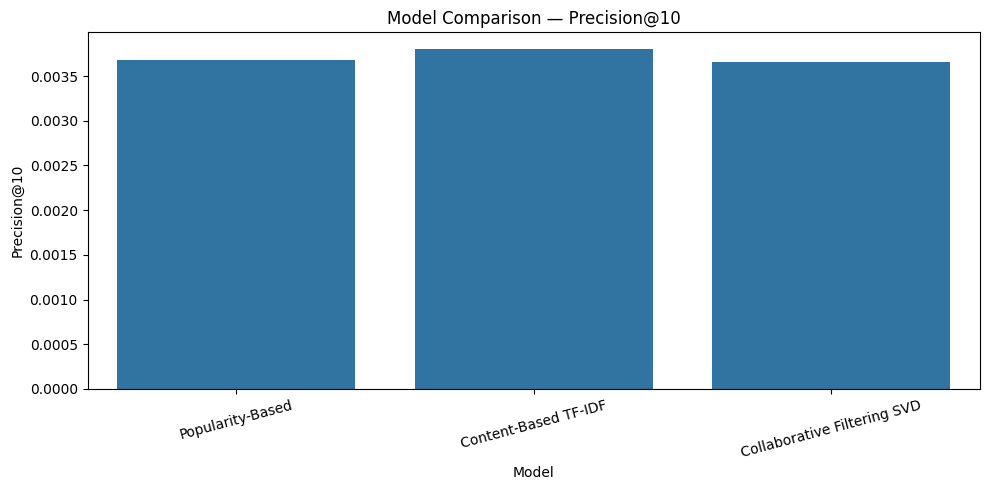

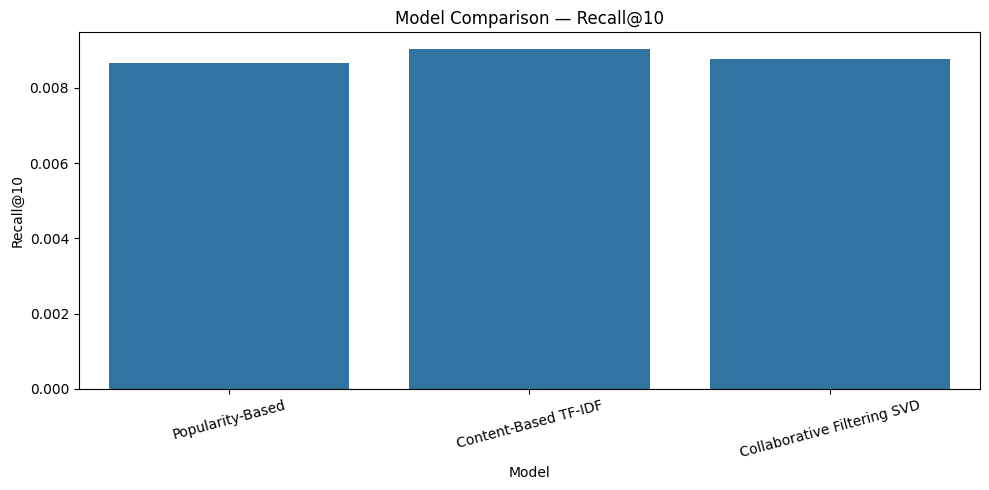

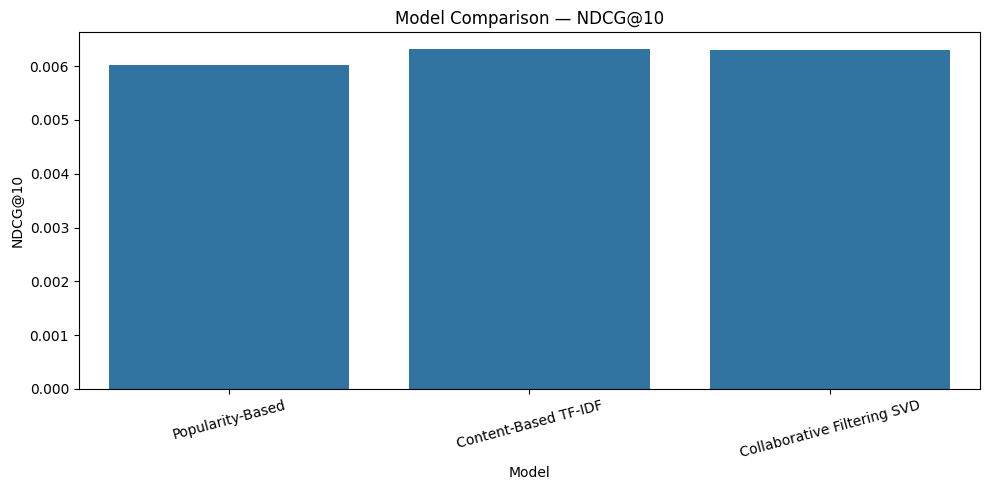

In [76]:
metrics_to_plot = [
    "Precision@10",
    "Recall@10",
    "NDCG@10"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=evaluation_results,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison — {metric}")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

In [77]:
display(
    evaluation_results.sort_values(
        "NDCG@10",
        ascending=False
    ).round(4)
)

,Model,Precision@10,Recall@10,NDCG@10,Catalog Coverage (%)
1,Content-Based TF-IDF,0.0038,0.0090,0.0063,99.8298
2,Collaborative Filtering SVD,0.0037,0.0088,0.0063,72.9362
0,Popularity-Based,0.0037,0.0087,0.0060,1.1064


In [78]:
display(
    evaluation_results.sort_values(
        "NDCG@10",
        ascending=False
    ).round(4)
)

,Model,Precision@10,Recall@10,NDCG@10,Catalog Coverage (%)
1,Content-Based TF-IDF,0.0038,0.0090,0.0063,99.8298
2,Collaborative Filtering SVD,0.0037,0.0088,0.0063,72.9362
0,Popularity-Based,0.0037,0.0087,0.0060,1.1064


In [79]:
import joblib
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

artifacts = {
    "products": products,
    "popularity_model": popularity_model,
    "product_features": product_features,
    "similarity_matrix": similarity_matrix,
    "product_index": product_index,
    "customer_to_idx": customer_to_idx,
    "product_ids": product_ids,
    "customer_factors": customer_factors,
    "product_factors": product_factors,
    "train_seen": train_seen,
    "evaluation_results": evaluation_results
}

joblib.dump(artifacts, MODEL_DIR / "recommendation_models.pkl")

print("All model artifacts saved successfully!")

All model artifacts saved successfully!
